# Lab 10: Explainability with Alibi
In this lab, you'll learn about the Alibi Explain library and implement global and local explanations of tabular and image classification models.

Alibi Explain is an open source Python library aimed at machine learning model inspection and interpretation. The focus of the library is to provide high-quality implementations of black-box, white-box, local and global explanation methods for classification and regression models.

Complete all the Deliverables mentioned below and show it to a TA for credit.

## Deliverables
- Finish all the TODOs in Section 2
- Generate PD Plots. Discuss your findings about model performance with the TA and answer Q1, Q2, and Q3:
     - Q1: Which features have higher importance in the prediction? (Section 2.1)
     - Q2: What can you conclude with the PD plots? (Section 2.2)
     - Q3: Discuss with the TA the results (heatmaps). (Section 2.2)
- Show final results  about the Anchor parameters and discuss them with the TA.
- Complete the SHAP section & discuss your findings with the TA.


## Getting Started
Clone this repository and run all cells in the notebook.

### Install Dependencies

For this assignment, make sure you have the required packages installed.
```
pip install -r requirements.txt
```
(If there are any major unsolvable issues prefer running this notebook on Google Colaboratory)

### Possible Issues with installing Alibi
`TypeError: issubclass() arg 1 must be a class` \
**Solution:** https://stackoverflow.com/questions/76313592/import-langchain-error-typeerror-issubclass-arg-1-must-be-a-class
<br><br>
If there's any more issues, please contact a TA to update this list (with a solution if its solved)

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

from alibi.explainers import PartialDependence, plot_pd, plot_pd_variance
from alibi.explainers import PartialDependenceVariance


2026-11-12 15:24:28.366772: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-12 15:24:28.369306: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-12 15:24:28.406502: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-12 15:24:28.406527: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-12 15:24:28.406549: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

2026-11-12 15:24:29.295549: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


## Section 1 - Data + Modeling
In this section, we will be setting up our data, perform some preprocessing and train a model.

### 1.1 Fetching the Dataset
We are going to use the The Boston Housing Dataset in the next experiment.
https://www.cs.toronto.edu/~delve/data/boston/bostonDetail.html


There are 14 attributes in each case of the dataset:
- CRIM - per capita crime rate by town
- ZN - proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS - proportion of non-retail business acres per town.
- CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)
- NOX - nitric oxides concentration (parts per 10 million)
- RM - average number of rooms per dwelling
- AGE - proportion of owner-occupied units built prior to 1940
- DIS - weighted distances to five Boston employment centres
- RAD - index of accessibility to radial highways
- TAX - full-value property-tax rate per $10,000
- PTRATIO - pupil-teacher ratio by town
- B - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
- LSTAT - % lower status of the population
- MEDV - Median value of owner-occupied homes in $1000's

In [2]:
df = pd.read_csv('BostonHousing.csv')
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


### 1.2 Dataset Preprocessing

Run the following code necessary to pre-process the data for alibi.

In [3]:
# extract feature names
feature_names = df.columns.tolist()
target_feature = 'medv'
feature_names.remove(target_feature)

# define target names
target_names = [target_feature]

#  define categorical columns
categorical_columns_names = []

# define categorical and numerical indices for later preprocessing
categorical_columns_indices = [feature_names.index(cn) for cn in categorical_columns_names]
numerical_columns_indices = [feature_names.index(fn) for fn in feature_names if fn not in categorical_columns_names]

# extract data
X = df[feature_names]
# define target column
y = df[target_feature]

# split data in train & test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [4]:
# define and fit the original encoder
oe = OrdinalEncoder().fit(X_train[categorical_columns_names])

# transform the categorical columns to ordinal encoding
X_train.loc[:, categorical_columns_names] = oe.transform(X_train[categorical_columns_names])
X_test.loc[:, categorical_columns_names] = oe.transform(X_test[categorical_columns_names])

# convert data to numpy
X_train, y_train = X_train.to_numpy(), y_train.to_numpy()
X_test, y_test = X_test.to_numpy(), y_test.to_numpy()

# define categorical mappings
categorical_names = {i: list(v) for (i, v) in zip(categorical_columns_indices, oe.categories_)}

In [5]:
# define numerical standard sclaer
num_transf = StandardScaler()

# define categorical one-hot encoder
cat_transf = OneHotEncoder(
    categories=[range(len(x)) for x in categorical_names.values()],
    handle_unknown='ignore',
)

# define preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_transf, categorical_columns_indices),
        ('num', num_transf, numerical_columns_indices),
    ],
    sparse_threshold=0
)


In [6]:
# fit preprocessor
preprocessor.fit(X_train)

# preprocess train and test datasets
X_train_ohe = preprocessor.transform(X_train)
X_test_ohe = preprocessor.transform(X_test)

### 1.3 Training the Model
Run the cell to fit the model to the dataset

In [7]:
# define and fit regressor - feel free to play with the hyperparameters
predictor = RandomForestRegressor(random_state=0)
predictor.fit(X_train_ohe, y_train)

# compute scores
print('Train score: %.2f' % (predictor.score(X_train_ohe, y_train)))
print('Test score: %.2f' % (predictor.score(X_test_ohe, y_test)))

Train score: 0.98
Test score: 0.77


## Section 2 - Explainability with Alibi
In this section, we will be finally using Alibi to explain our trained model using different techniques. Fill in the TODOs and generate plots where required.

In [8]:
# Creating a Prediction Function - Includes pipeline from preprocessing to prediction
prediction_fn = lambda x: predictor.predict(preprocessor.transform(x))

#### Computing Explanations
We will finally be computing explanations for selected features. Play around with different methods.

### 2.1 Partial Dependence Variance (PDV)  - Feature Importance

Partial Dependence Variance is a method to compute the global feature importance or the feature interaction of a pair of features.

Complete the code below and answer Q1

**Q1: Which features have higher importance in the prediction?**

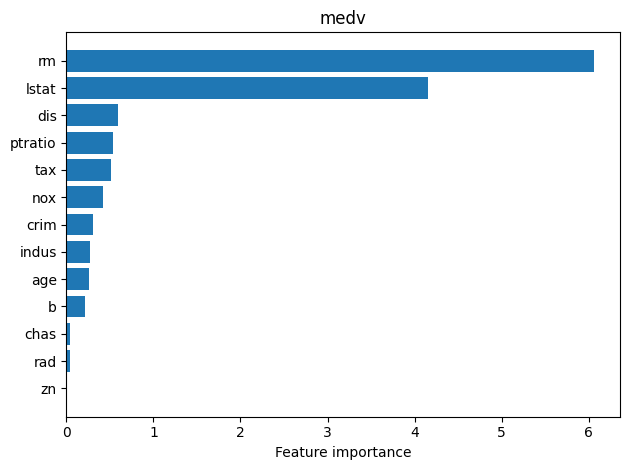

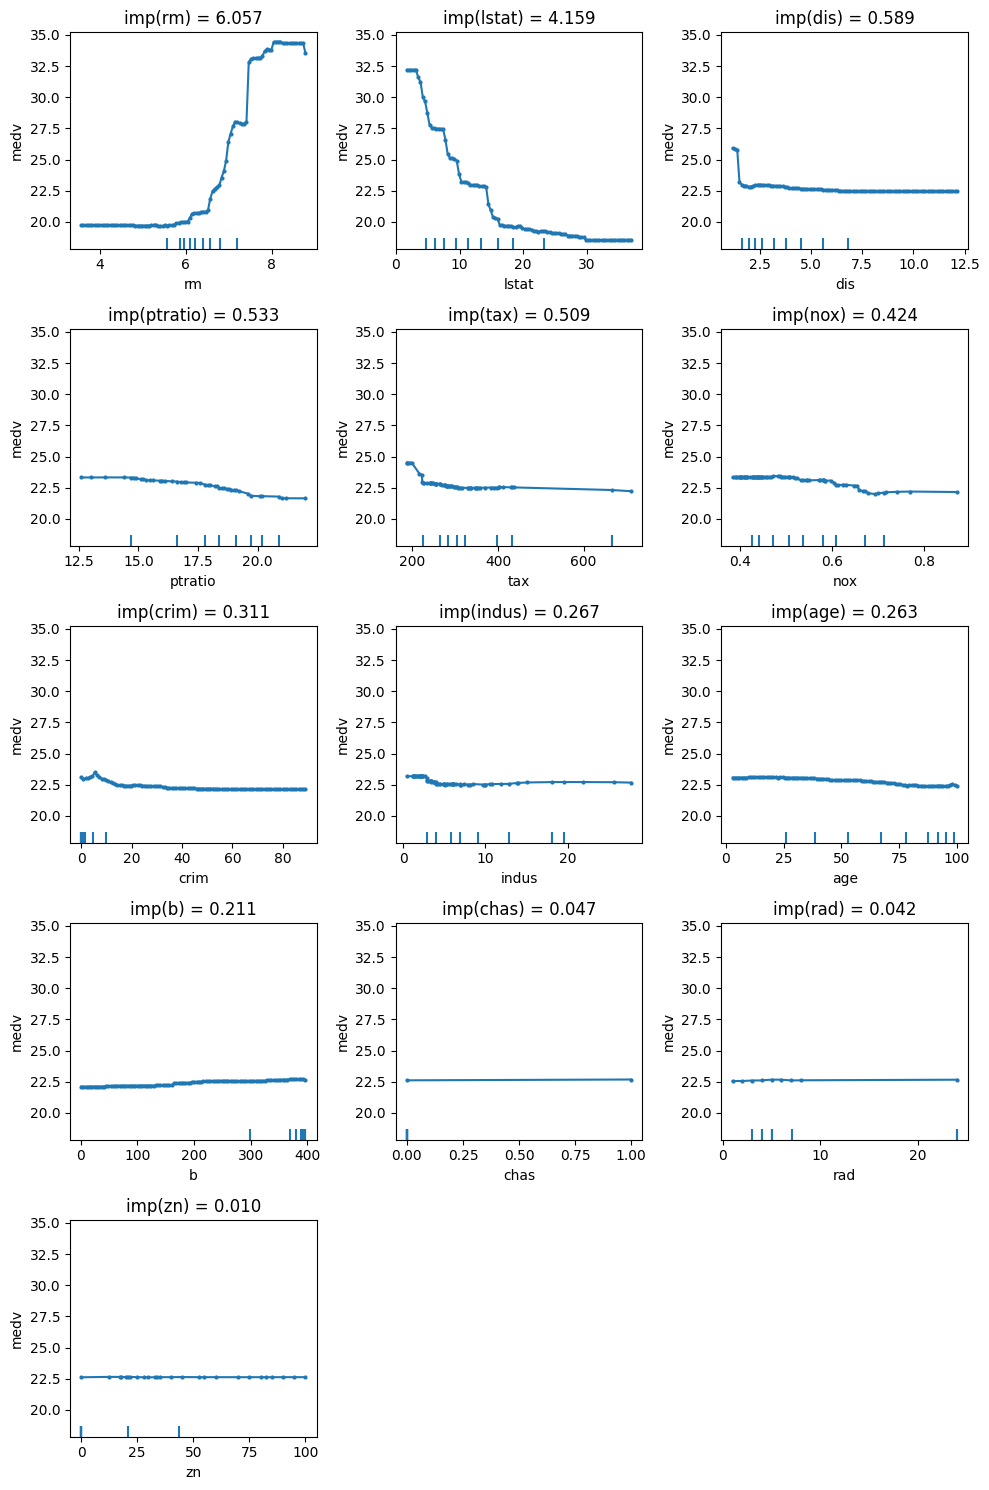

In [9]:
# Determine which features are more important using Partial Dependence Variance
explainer = PartialDependenceVariance(predictor=prediction_fn,
                                      feature_names=feature_names,
                                      categorical_names=categorical_names,
                                      target_names=target_names)

exp_importance = explainer.explain(X=X_train, method='importance')

# plot the results
plot_pd_variance(exp=exp_importance)
plot_pd_variance(exp=exp_importance, summarise=False, fig_kw={'figheight': 15, 'figwidth': 10});

**Answer Q1:** Two features dominate. **`rm`** (avg rooms per dwelling, importance ≈ 6.1) and **`lstat`** (% lower status population, ≈ 4.2) are far ahead of everything else. The next group is much weaker: `dis` (≈ 0.59), `ptratio` (≈ 0.53), `tax` (≈ 0.51) and `nox` (≈ 0.42). `chas`, `rad` and `zn` are close to zero, so the model basically ignores them. In other words, the random forest prices a house mostly by how big it is and how well off the neighborhood is.

### 2.2 Partial Dependence (PD)

Partial Dependence is a method to visualize the marginal effect that one or two features have on the predicted outcome of a machine learning model.

By inspecting the PD plots, one can understand whether the relation between a feature/pair of features is, for example, a simple linear or quadratic relation, whether it presents a monotonically increasing or decreasing trend, or reveal a more complex response.

#### Computing Explanations
We will finally be computing explanations. You can try different modes of `kind` to see different visualizations. (Suggestion: use `both` to visualize all data)

As per the documentation,
> `kind` - If set to `average`, then only the partial dependence (PD) averaged across all samples from the dataset is returned. If set to `individual`, then only the individual conditional expectation (ICE) is returned for each individual from the dataset. Otherwise, if set to `both`, then both the PD and the ICE are returned.


Run the following code with all features and also selecting some specific features.

**Q2: What can you conclude?**

In [10]:
# Define explainer
explainer_pd = PartialDependence(predictor=prediction_fn,
                       feature_names=feature_names,
                       categorical_names=categorical_names,
                       target_names=target_names)


In [11]:
# you can also compute explanations for selected features.
# zn	indus	chas	nox	rm	age	dis	rad	tax	ptratio	b	lstat	medv

# Select features to compute explanations for: the top 6 by PD variance importance (Section 2.1)
selected_feature_names = ['rm', 'lstat', 'dis', 'ptratio', 'tax', 'nox']
features = [feature_names.index(f) for f in selected_feature_names]
features

[5, 12, 7, 10, 9, 4]

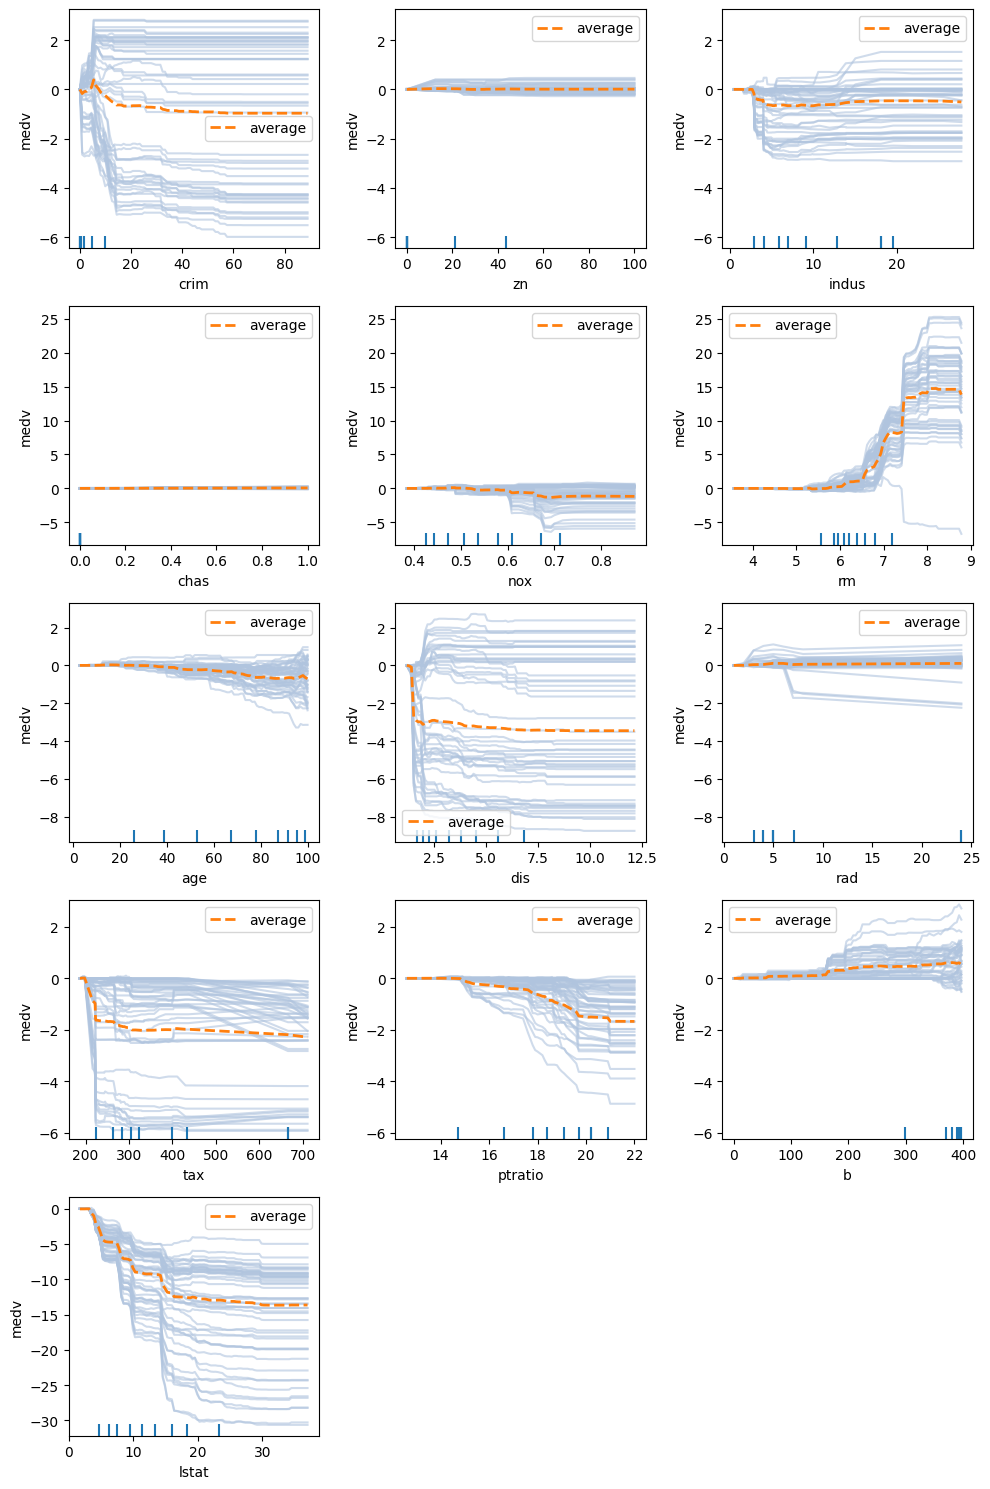

In [12]:
# compute explanations for ALL features
exp = explainer_pd.explain(X=X_train,
                           kind='both') # kind = [both, individual, average]

# plot partial dependence curves
plot_pd(exp=exp,
        n_cols=3,
        n_ice=50,
        sharey='row',
        center=True,
        fig_kw={'figheight': 15, 'figwidth': 10});

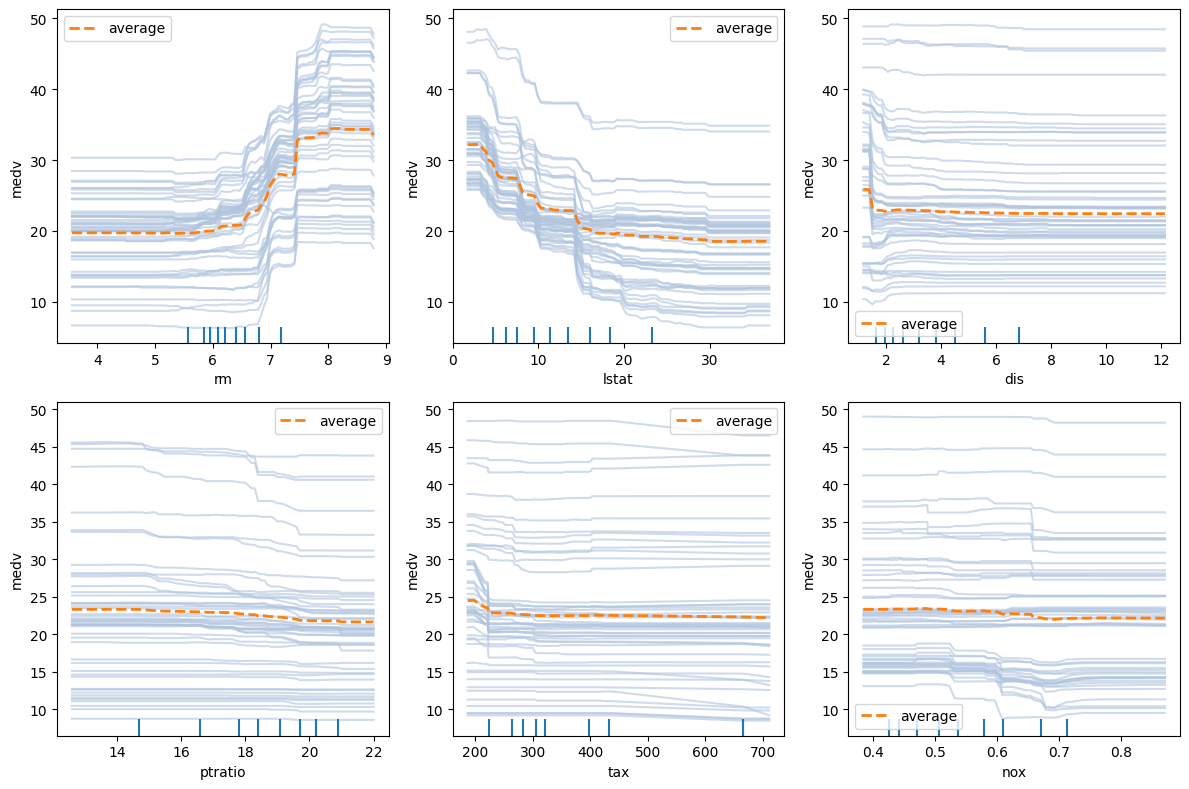

In [13]:
# compute explanations for the SELECTED features only
exp_selected = explainer_pd.explain(X=X_train,
                                    features=features,
                                    kind='both')

# not centered here, so the y-axis shows the actual predicted medv (in $1000s)
plot_pd(exp=exp_selected,
        n_cols=3,
        n_ice=50,
        sharey='row',
        center=False,
        fig_kw={'figheight': 8, 'figwidth': 12});

**Answer Q2:**
* **`rm` has a strong positive, threshold shaped effect.** The PD curve is flat at about \$20k for 4 to 6 rooms, starts rising after about 6.5 rooms, and jumps to about \$33k to \$34k after about 7.4 rooms. So the model treats "big house" almost like a step, not a linear trend.
* **`lstat` has a strong negative, nonlinear effect.** Predicted price drops from about \$32k at lstat ≈ 2% to about \$20k by lstat ≈ 15%, then flattens out (about \$18.6k at 37%). Most of the effect happens at the low end.
* **`dis`, `tax`, `ptratio`, `nox` have small effects.** Each moves the average prediction by only about \$1k to \$3.5k: very close to employment centers (`dis` < 2) and very low `tax` raise price, high `ptratio` and high `nox` (> 0.65) lower it. Everything else is basically flat.
* **ICE lines are mostly parallel** to the PD line for `rm` and `lstat`, so the effect is fairly consistent across houses. The spread in jump size for `rm` (some lines jump more than \$15k, some barely move) hints at an interaction, which the two feature plots below check.
* The curves are step shaped because the model is a random forest (piecewise constant splits), and the rug marks show there is little data for `rm` > 8 or `lstat` > 30, so those flat tails are less trustworthy.

### Check Partial Dependence for Two Features
Choose pairs of features to visualize their relationships and interactions with each other. These plots may be a bit confusing so try your best to explain whatever you understand to the TA.
We suggest to select a feature with high  and low importance. 
You can also try different combinations of features in order to get better conclusion.

**Q3: Discuss with the TA the results.**

In [14]:
# select combination of features: the two most important features (high + high)
FEATURE1 = 'lstat'
FEATURE2 = 'rm'

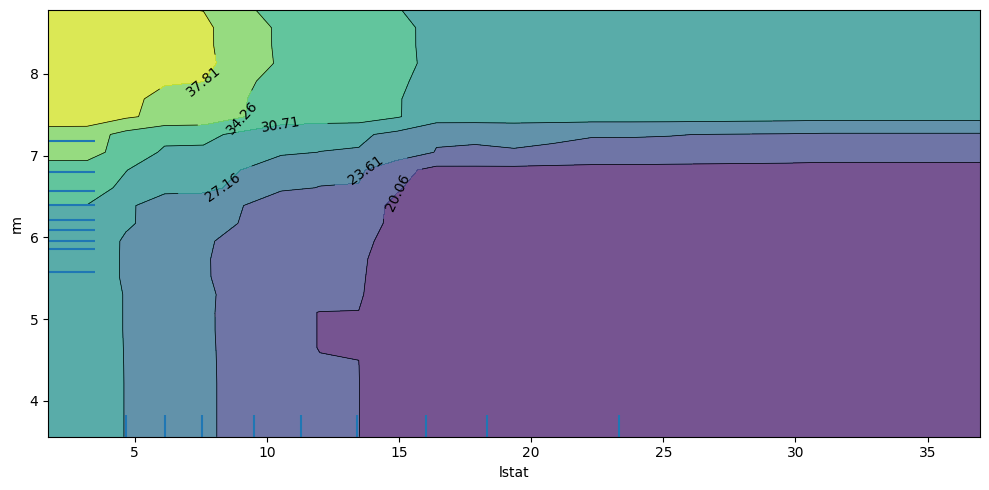

In [15]:
combined_features = [(feature_names.index(FEATURE1), feature_names.index(FEATURE2))]

# compute explanations
comb_exp = explainer_pd.explain(X=X_train,
                        features=combined_features,
                        kind='average',
                        grid_resolution=25) # kind = [both, individual, average]

# plot partial dependece curves
plot_pd(exp=comb_exp,
        n_cols=3,
        n_ice=50,
        sharey='row',
        center = True,
        fig_kw={'figheight': 5, 'figwidth': 10});


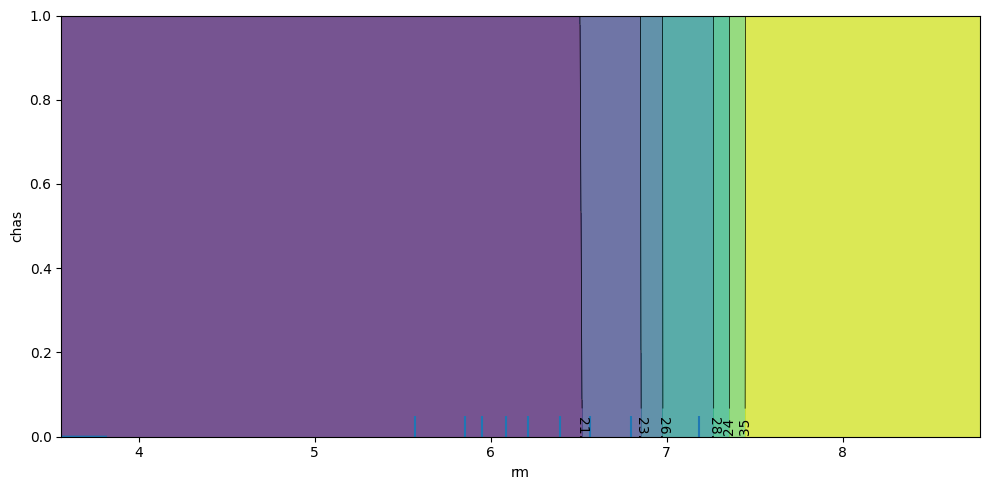

In [16]:
# Second pair: a high-importance feature with a low-importance feature (high + low)
FEATURE1_B = 'rm'
FEATURE2_B = 'chas'
comb_exp_b = explainer_pd.explain(X=X_train,
                                  features=[(feature_names.index(FEATURE1_B), feature_names.index(FEATURE2_B))],
                                  kind='average',
                                  grid_resolution=25)
plot_pd(exp=comb_exp_b,
        n_cols=3,
        sharey='row',
        center=True,
        fig_kw={'figheight': 5, 'figwidth': 10});

In [17]:
# Quantify how much each pair actually interacts (PD Variance, method='interaction')
pairs = [('lstat', 'rm'), ('rm', 'chas'), ('lstat', 'dis')]
exp_interaction = explainer.explain(X=X_train,
                                    features=[(feature_names.index(a), feature_names.index(b)) for a, b in pairs],
                                    method='interaction')
for (a, b), score in zip(pairs, exp_interaction.data['feature_interaction'][0]):
    print(f'{a:>6} x {b:<6} interaction strength: {score:.3f}')

 lstat x rm     interaction strength: 0.255
    rm x chas   interaction strength: 0.033
 lstat x dis    interaction strength: 0.548


**Answer Q3 (heatmaps):**
* **`lstat` × `rm` (high + high importance):** The best predictions (about \$38k+) are in the top left corner (many rooms and low `lstat`), and the worst (about \$20k) are in the bottom right (few rooms and high `lstat`). The L shaped contours mostly come from each feature's own threshold (rooms only matter above about 7, `lstat` mostly matters below about 15%), not from the two features depending on each other. Going from 3.6 to 8.1 rooms adds about \$10.7k at the lowest `lstat` and about \$12.5k at the highest `lstat`, and going from low to high `lstat` costs about \$13.6k for small houses vs about \$11.8k for big ones. So the effects are close to additive, with only a weak interaction (PDV interaction strength ≈ 0.25, tiny compared with their individual importances of 4 to 6).
* **`rm` × `chas` (high + low importance):** `chas` is stored as a number, so the plot is a contour map with `chas` on the y axis. Every color boundary is perfectly vertical: the price changes along `rm` but never with `chas`, so river access adds essentially nothing at any room count. Interaction strength is ≈ 0.03, which confirms no interaction. This is what a low importance feature looks like in a two feature PD plot.
* **Bonus check, `lstat` × `dis`:** this pair has the highest interaction score of the three (≈ 0.55), so it would be the next heatmap worth plotting, but it is still small in absolute terms.
* Caveat: PD assumes features are independent, but `rm` and `lstat` are negatively correlated in real data, so corners like "8 rooms with 35% lstat" are mostly extrapolation.

## 2.3 Anchors
This algorithm provides model-agnostic (black box) and human interpretable explanations suitable for classification models applied to images, text and tabular data. The idea behind anchors is to explain the behaviour of complex models with high-precision rules called anchors. These anchors are locally sufficient conditions to ensure a certain prediction with a high degree of confidence. Run all the cells and try different parameters to see how this algorithm works.

We will be explaining predictions from the ImageNet model on the cats dataset.

In [18]:
import tensorflow as tf
import matplotlib

import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image
from alibi.datasets import load_cats
from alibi.explainers import AnchorImage

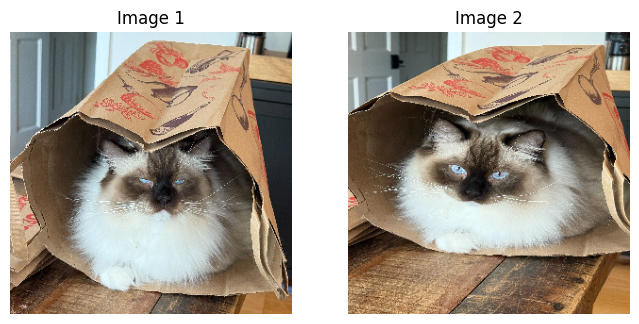

In [19]:
# Path to your image

# You are free to play around with other images. 
# Here are two pictures of Professor Bogdan's beautiful cat.
img1_path = "hyPURRmeter_fineMEOWing.jpg"
img2_path = "your_TA.jpg"

def load_and_preprocess(img_path):
    img = image.load_img(img_path, target_size=(299, 299))
    img_array = image.img_to_array(img)
    # copy: preprocess_input scales in place and would overwrite img_array (used for display)
    img_preprocessed = preprocess_input(np.expand_dims(img_array.copy(), axis=0))
    return img_array, img_preprocessed

# Load and preprocess both images
img1_array, img1_preprocessed = load_and_preprocess(img1_path)
img2_array, img2_preprocessed = load_and_preprocess(img2_path)

# Display both images
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1_array.astype('uint8'))
plt.title("Image 1")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2_array.astype('uint8'))
plt.title("Image 2")
plt.axis('off')
plt.show()


In [20]:
#load pre-trained model
model = InceptionV3(weights='imagenet')
predict_fn = lambda x: model.predict(x, verbose=0)  # verbose=0 hides thousands of progress bars during Anchor sampling

In [21]:
#check model predictions for both images.
for idx, (arr, prep) in enumerate([(img1_array, img1_preprocessed), (img2_array, img2_preprocessed)], start=1):
    preds = model.predict(prep)
    decoded = decode_predictions(preds, top=3)[0]
    print(f"\nTop predictions for Image {idx}:")
    for _, label, prob in decoded:
        print(f"  {label:20s}: {prob:.3f}")

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 1s 978ms/step



Top predictions for Image 1:
  Persian_cat         : 0.502
  Siamese_cat         : 0.139
  carton              : 0.055


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 114ms/step



Top predictions for Image 2:
  Persian_cat         : 0.574
  Siamese_cat         : 0.157
  crate               : 0.008


In [22]:
#create and run anchorImage explainer
image_shape = (299, 299, 3)
segmentation_fn = 'slic'  # Superpixel segmentation
kwargs = {'n_segments': 15, 'compactness': 20, 'sigma': .5, 'start_label': 0}


In [23]:
explainer = AnchorImage(
    predict_fn,
    image_shape=image_shape,
    segmentation_fn=segmentation_fn,
    segmentation_kwargs=kwargs,
    images_background=None
)


In [24]:
#choose an image to explain

image_to_explain = img1_preprocessed[0]  # or img2_preprocessed[0]
np.random.seed(0)

explanation = explainer.explain(image_to_explain, threshold=.95, p_sample=.5, tau=0.25)


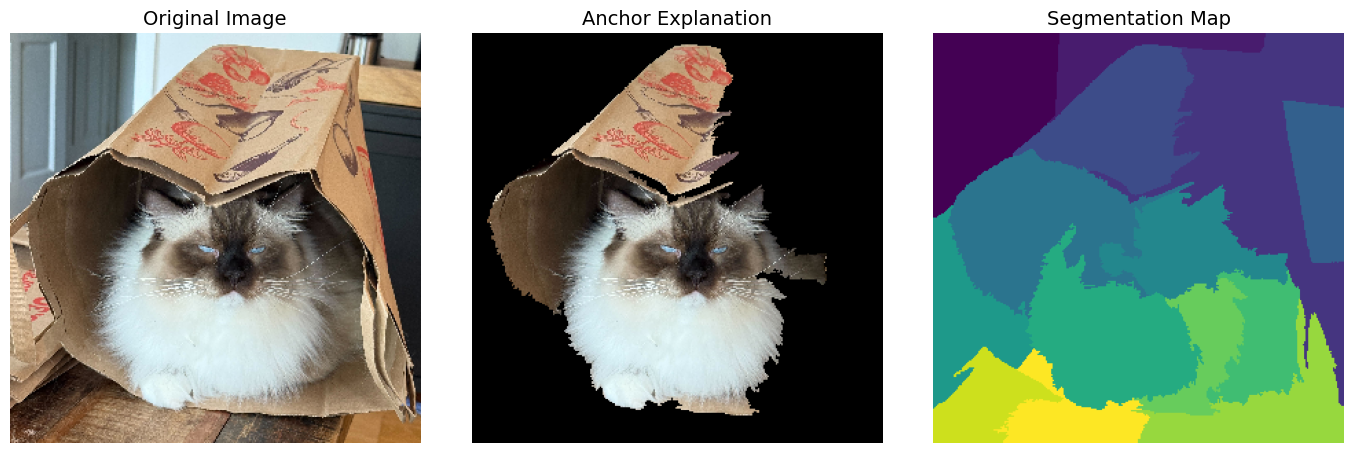

In [25]:
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 3, 1)
plt.imshow(img1_array.astype('uint8'))  # use img2_array if you explained Image 2
plt.title("Original Image", fontsize=14)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(explanation.anchor.astype('uint8'))
plt.title("Anchor Explanation", fontsize=14)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(explanation.segments)
plt.title("Segmentation Map", fontsize=14)
plt.axis('off')

plt.tight_layout()
plt.show()

### 2.3.1 Trying a different parameter setting
Same image (Image 1) and same `threshold=0.95`, but with finer superpixels: `n_segments` 15 → 35. Everything else is unchanged so the difference comes from the segmentation alone.

In [26]:
kwargs_fine = {'n_segments': 35, 'compactness': 20, 'sigma': .5, 'start_label': 0}

explainer_fine = AnchorImage(
    predict_fn,
    image_shape=image_shape,
    segmentation_fn=segmentation_fn,
    segmentation_kwargs=kwargs_fine,
    images_background=None
)

np.random.seed(0)
explanation_fine = explainer_fine.explain(image_to_explain, threshold=.95, p_sample=.5, tau=0.25)

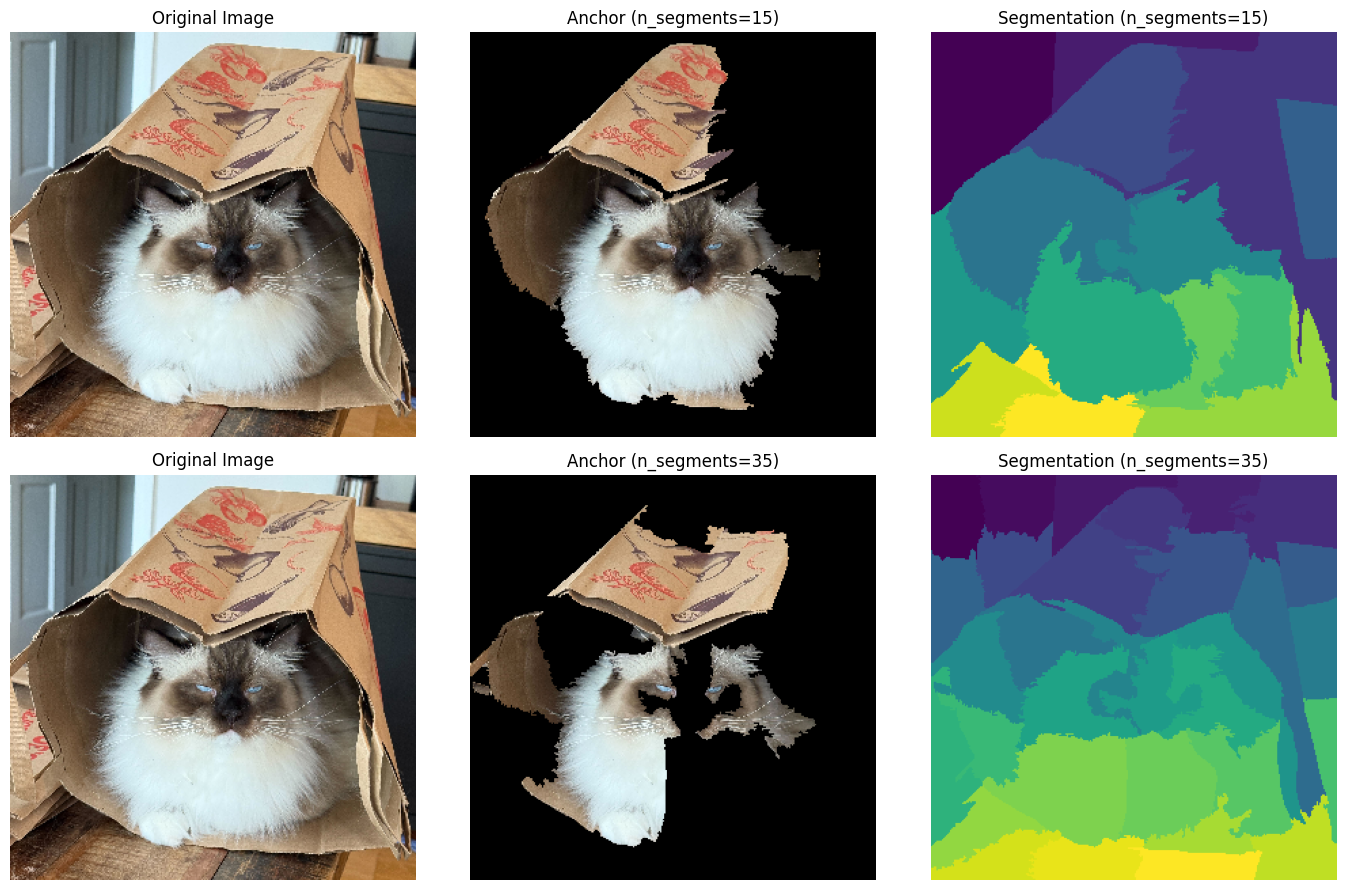

n_segments=15: anchor = superpixels [6, 10, 8, 5, 3] (5 of 14), precision = 1.000, coverage = 0.033
n_segments=35: anchor = superpixels [18, 19, 25, 8, 14, 6, 15] (7 of 32), precision = 0.974, coverage = 0.007


In [27]:
plt.figure(figsize=(14, 9))
for row, (name, exp_) in enumerate([('n_segments=15', explanation), ('n_segments=35', explanation_fine)]):
    plt.subplot(2, 3, row*3 + 1); plt.imshow(img1_array.astype('uint8')); plt.title('Original Image'); plt.axis('off')
    plt.subplot(2, 3, row*3 + 2); plt.imshow(exp_.anchor.astype('uint8')); plt.title(f'Anchor ({name})'); plt.axis('off')
    plt.subplot(2, 3, row*3 + 3); plt.imshow(exp_.segments); plt.title(f'Segmentation ({name})'); plt.axis('off')
plt.tight_layout()
plt.show()

for name, exp_ in [('n_segments=15', explanation), ('n_segments=35', explanation_fine)]:
    print(f"{name}: anchor = superpixels {exp_.data['raw']['feature']} "
          f"({len(exp_.data['raw']['feature'])} of {exp_.segments.max() + 1}), "
          f"precision = {float(np.ravel(exp_.precision)[0]):.3f}, coverage = {exp_.coverage:.3f}")

**Anchor results and answers**

InceptionV3 predicts **Persian_cat** for Image 1 (0.50), then Siamese_cat (0.14) and **carton** (0.06).

| Setting | Anchor superpixels | Precision | Coverage |
|---|---|---|---|
| `n_segments=15`, `threshold=0.95` | 5 of 14 | 1.000 | 0.033 |
| `n_segments=35`, `threshold=0.95` | 7 of 32 | 0.974 | 0.007 |

1. **What did the explainer focus on?** With 15 segments, the anchor is the cat's face and fluffy white chest plus the top and left parts of the paper bag. With 35 segments, the anchor gets more specific: the face, the eye region, part of the chest fur, and again pieces of the bag.
2. **Does it make sense for the label?** Mostly yes. The face, blue eyes and long white fur are exactly what separates a Persian from other cats. But the bag keeps showing up in the anchor in both settings, so the model is also using background context. This matches the third prediction being "carton".
3. **What if the region looks unrelated to the object?** It means the model may depend on spurious context instead of the object itself (like the classic "husky vs wolf decided by snow" example). The prediction could break if the same cat appears without the bag. It can also be an artifact of segmentation: with only 15 large superpixels, a single segment mixes cat and bag, so the anchor is forced to include both.

**Parameter discussion:** More segments (15 → 35) gives a finer, tighter anchor that isolates the face better, but it needs more superpixels (7 vs 5) and has much lower coverage (0.007 vs 0.033). That is a less general rule. Fewer segments gives coarser but more general anchors. `threshold` works in a similar direction: a higher threshold demands higher precision, which usually forces a bigger anchor with lower coverage.

Questions:
1. What part of your image did the Anchor explainer focus on?
2. Does the highlighted region make sense when you compare it to the model's predicted label?
3. What does it mean if the highlighted region seems unrelated to the object?

## 3 SHAP
SHAP is a unified framework for interpreting predictions based on Shapley values from cooperative game theory.
It attributes the prediction of a model to each input feature by quantifying how much that feature contributed to increasing or decreasing the final prediction compared to the model’s average output.
In other words, SHAP tells us:
“If I remove or change this feature, how would the model’s prediction change?”
SHAP values are additive, meaning that for each prediction, the sum of all feature contributions equals the model’s output minus the baseline (average) prediction.
This makes SHAP both mathematically grounded and visually interpretable.
In this section, you will:
1. Generate global feature importance using SHAP summary plots.
2. Analyze local explanations for a specific instance using waterfall plots.
3. Compare SHAP’s results with your earlier Partial Dependence and Anchor explanations to see whether they agree.

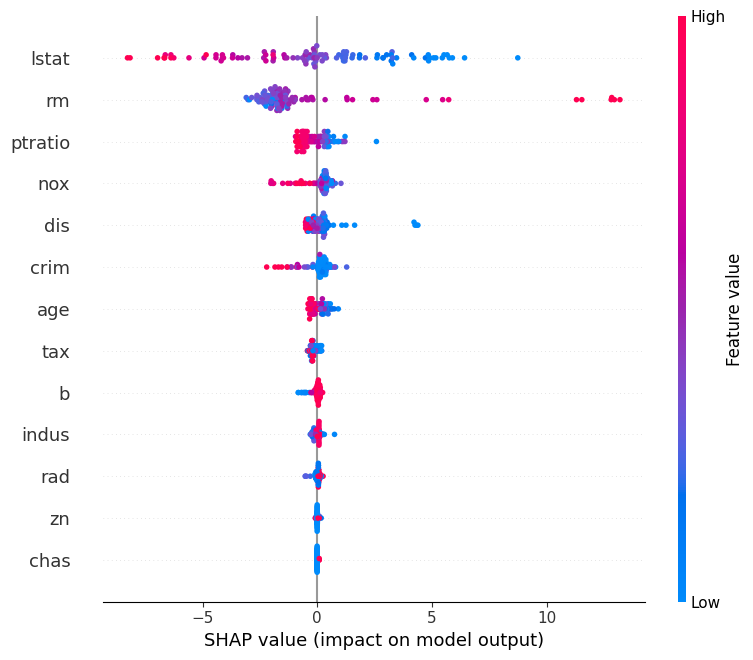

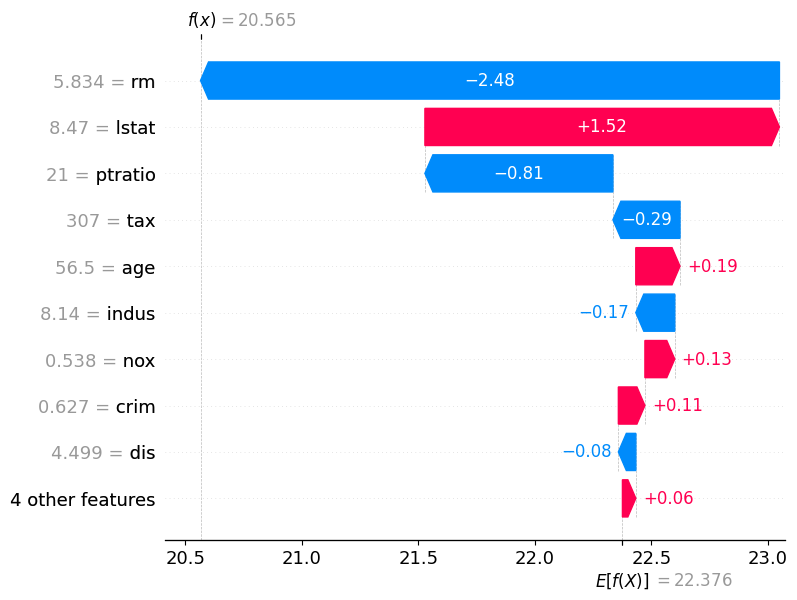

In [28]:
import shap
import matplotlib.pyplot as plt

# Define SHAP explainer for the Random Forest regressor
shap_explainer = shap.Explainer(predictor, X_train_ohe)

# Compute SHAP values
shap_values = shap_explainer(X_test_ohe)
# Label with real feature names and unscaled values so plots show 'rm' instead of 'Feature 5'
shap_values.feature_names = feature_names
shap_values.data = X_test

# Global feature importance
shap.summary_plot(shap_values, X_test, feature_names=feature_names)
# plt.title("Global SHAP Feature Importance")
# plt.show()

# Local explanation for one instance
idx = 5
shap.plots.waterfall(shap_values[idx])


**Answer Q4:** SHAP's top two are **`lstat`** (mean |SHAP| ≈ 2.8) and **`rm`** (≈ 2.45), followed far behind by `ptratio` (≈ 0.53), `nox` (≈ 0.47), `dis` (≈ 0.44) and `crim` (≈ 0.40). `chas`, `zn` and `rad` are near zero. This **mostly matches the PD findings**: the same two features dominate, the same middle group follows, and the same features are ignored. The directions also match: high `lstat` pushes price down (red dots on the left), high `rm` pushes price up.

The main difference is that **SHAP ranks `lstat` first while PDV ranks `rm` first**. PDV measures how much the *average curve* moves over the whole grid, and the `rm` curve has a large jump at 7 to 7.5 rooms. But most houses have 5.5 to 6.5 rooms, where the `rm` curve is flat, so on a typical house `rm` contributes little (the big blue cluster near −2 and the few big red dots at +11 to +13). `lstat` instead varies a lot across normal houses, so its average absolute contribution is larger. Some smaller features also swap order (`ptratio`/`nox` vs `dis`/`tax`) because SHAP accounts for feature interactions and correlation in a way PD does not.

**Local example (test row 5):** prediction \$20.6k vs baseline \$22.4k. The small house (`rm` = 5.8, −2.48) and high `ptratio` (21, −0.81) pull it down, while a moderately low `lstat` (8.5%, +1.52) pulls it up.

## 4 Reflection & comparison
You have now explored three complementary ways to understand your model’s behavior:
Partial Dependence (PD): shows average feature effects (global trend).
Anchors: provides human-readable rules explaining specific predictions (local).
SHAP: quantifies feature contributions for each prediction (both global and local).
Each method offers a different lens:
1. PD plots summarize what the model learns overall,
2. Anchors explain why a single decision was made, and
3. SHAP connects both by showing how much each feature contributed numerically.
Use this final section to connect the dots between them.

Questions to answer:

1. Do any of the top features raise ethical or fairness concerns?
Could the model be relying on socioeconomic or location-based variables in ways that might bias predictions?

**Answer:** Yes. `lstat` (% "lower status" population) is the single strongest feature in SHAP and second in PDV, and it is a socioeconomic proxy, so the model directly prices homes lower in poorer neighborhoods. That can reinforce existing inequality if it is used for lending, insurance or appraisal. `b` is defined from the proportion of Black residents per town, which is a protected attribute. Its importance is small here (PDV ≈ 0.21, mean |SHAP| ≈ 0.12), but it should not be a model input at all, and dropping it does not fully fix the issue, because `lstat`, `crim`, `nox`, `dis` and `rad` are location features that can act as proxies for race and income (redlining effects).

2. Do SHAP’s most important features agree with those found by PD plots or Anchor explanations?
If they differ, why might that happen?


**Answer:** SHAP and PD agree on the big picture (`rm` and `lstat` far ahead, `chas`/`zn`/`rad` ignored) but swap the top two, because PDV measures the spread of the average curve while SHAP averages per instance contributions over the actual data distribution. Anchors cannot be compared directly, since they were run on a different model (InceptionV3 on images) and only explain one local prediction. Conceptually they agree with SHAP's local view: both show that a few key regions or features drive one prediction, and both can reveal context the model should not rely on (the paper bag).

3. Write a short paragraph (3 sentences max) summarizing what your model relies on and how confident you are in its interpretability.


**Answer (Q5):** The model relies almost entirely on house size (`rm`) and neighborhood socioeconomic status (`lstat`), with small contributions from `ptratio`, `nox`, `dis` and `tax`. PDV, PD/ICE and SHAP all agree on this, so I am fairly confident in the global interpretation, though less confident in sparse regions and in the PD heatmaps, since `rm` and `lstat` are correlated. The reliance on `lstat` and the presence of the race based `b` feature raise fairness concerns, so `b` should be removed and the model should be audited for proxy bias before any real use.

### References
1. https://docs.seldon.io/projects/alibi/en/stable/examples/pdp_regression_bike.html
2. https://docs.seldon.io/projects/alibi/en/stable/methods/PartialDependence.html
3. https://docs.seldon.io/projects/alibi/en/stable/examples/anchor_image_imagenet.html
